# Principal component analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/04-unsupervised/pca/pca-notebook.ipynb)

Companion notebook for the *Principal component analysis* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** the Wine data (178 wines, 13 chemical measurements, 3 cultivars). PCA does not use the cultivar.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
Q = 2

X_raw, y = load_wine(return_X_y=True)
n, d = X_raw.shape

## 1. Center and standardize

The features use different units, so each one becomes $\tilde{x}_{ij} = \dfrac{x_{ij} - \bar{x}_j}{s_j}$: mean 0 and spread 1.

In [2]:
X = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)
print("same result:", np.allclose(X, StandardScaler().fit_transform(X_raw)))

same result: True


## 2. Covariance and eigenvectors

$\mathbf{S} = \frac{1}{n}\mathbf{X}^\top\mathbf{X}$. The components are its eigenvectors, $\mathbf{S}\,\mathbf{w}_k = \lambda_k \mathbf{w}_k$,
sorted from the largest eigenvalue down. scikit-learn divides by $n - 1$ instead of $n$, and the sign of each direction is arbitrary.

In [3]:
S = X.T @ X / n
eigenvalues, W = np.linalg.eigh(S)
order = np.argsort(eigenvalues)[::-1]
eigenvalues, W = eigenvalues[order], W[:, order]

pca = PCA().fit(X)
print("same variances:", np.allclose(eigenvalues, pca.explained_variance_ * (n - 1) / n))
print("same directions (up to sign):", np.allclose(np.abs(W.T), np.abs(pca.components_)))

same variances: True
same directions (up to sign): True


## 3. Scores: the new coordinates

The score of example $i$ on component $k$ is $z_{ik} = \mathbf{w}_k^\top \tilde{\mathbf{x}}_i$. The scores are uncorrelated
and the variance of column $k$ is $\lambda_k$.

variances are the eigenvalues: True
same scores (up to sign): True


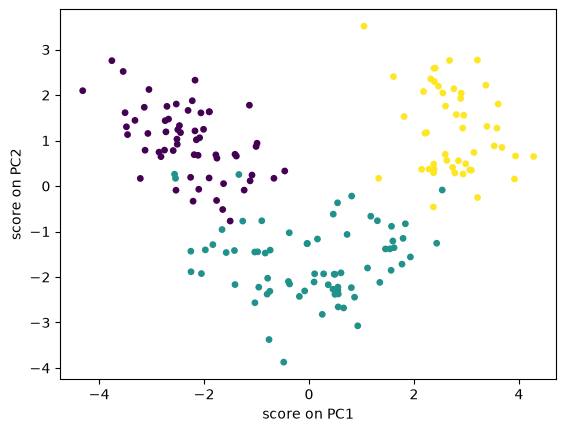

In [4]:
Z = X @ W
print("variances are the eigenvalues:", np.allclose(Z.var(axis=0), eigenvalues))
print("same scores (up to sign):", np.allclose(np.abs(Z), np.abs(pca.transform(X))))

plt.scatter(Z[:, 0], Z[:, 1], c=y, s=15)
plt.xlabel("score on PC1")
plt.ylabel("score on PC2")
plt.show()

Color shows the cultivar, which PCA never saw: two scores out of 13 features already separate the three groups.

## 4. Keeping fewer components

Rebuild each example from $q$ scores: $\hat{\mathbf{x}}_i = \bar{\mathbf{x}} + \sum_{k=1}^{q} z_{ik}\,\mathbf{w}_k$.
The average squared error is the variance left out, $\sum_{k=q+1}^{d} \lambda_k$.

In [5]:
X_hat = Z[:, :Q] @ W[:, :Q].T
error = ((X - X_hat) ** 2).sum(axis=1).mean()
print("error equals dropped variance:", np.isclose(error, eigenvalues[Q:].sum()))

pca_q = PCA(n_components=Q).fit(X)
print("same reconstruction:", np.allclose(X_hat, pca_q.inverse_transform(pca_q.transform(X))))

error equals dropped variance: True
same reconstruction: True


Here $\bar{\mathbf{x}} = \mathbf{0}$ because the data was already centered.

## 5. How many components: explained variance

$\text{PVE}_k = \lambda_k / \sum_j \lambda_j$ and $\text{CPVE}_q = \sum_{k \le q} \lambda_k / \sum_j \lambda_j$. Choose $q$ at the elbow or at a target such as 80%.

same result: True


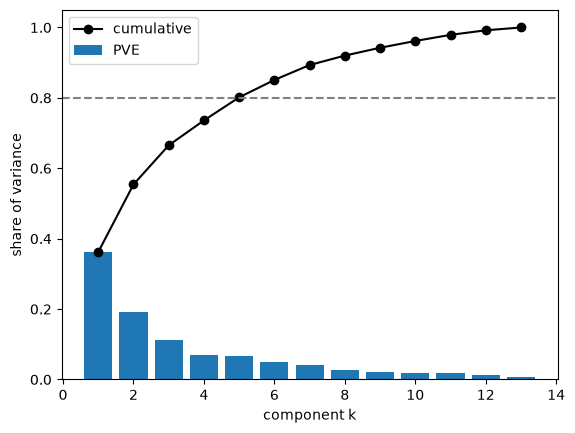

In [6]:
pve = eigenvalues / eigenvalues.sum()
print("same result:", np.allclose(pve, pca.explained_variance_ratio_))

components = np.arange(1, d + 1)
plt.bar(components, pve, label="PVE")
plt.plot(components, np.cumsum(pve), marker="o", color="black", label="cumulative")
plt.axhline(0.8, linestyle="--", color="gray")
plt.xlabel("component k")
plt.ylabel("share of variance")
plt.legend()
plt.show()

## Exercises

1. Run section 2 on `X_raw` without standardizing. Which feature dominates PC1, and why?
2. Find the smallest $q$ with $\text{CPVE}_q \ge 0.8$ and compare with `PCA(n_components=0.8)`.
3. Look at `W[:, 0]`: which three features have the largest weights (in absolute value) on PC1?